In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Completa: construye el degradado de 5x5
gris = np.tile(
    np.linspace(0, 255, 5, dtype=np.uint8),
    (5, 1)
)
# Completa: imprime shape, dtype y mean()
print("Shape:", gris.shape)
print("Dtype:", gris.dtype)
print("Media:", gris.mean())
print("Matriz:")
print(gris)

Shape: (5, 5)
Dtype: uint8
Media: 127.2
Matriz:
[[  0  63 127 191 255]
 [  0  63 127 191 255]
 [  0  63 127 191 255]
 [  0  63 127 191 255]
 [  0  63 127 191 255]]


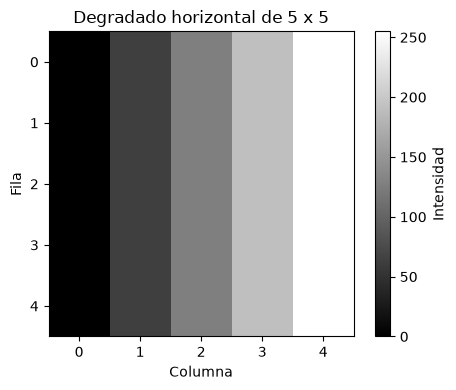

Imagen guardada como gris_tema6.png


In [3]:
# Completa: visualiza y guarda la imagen
plt.figure(figsize=(5, 4))

plt.imshow(
    gris,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest"
)

plt.colorbar(label="Intensidad")
plt.title("Degradado horizontal de 5 x 5")
plt.xlabel("Columna")
plt.ylabel("Fila")
plt.tight_layout()

plt.savefig("gris_tema6.png", dpi=150, bbox_inches="tight")
plt.show()

print("Imagen guardada como gris_tema6.png")

In [4]:
# Completa: recorte de la mitad derecha
recorte = gris[:, 2:5]

print("Shape del recorte:", recorte.shape)
print(recorte)

Shape del recorte: (5, 3)
[[127 191 255]
 [127 191 255]
 [127 191 255]
 [127 191 255]
 [127 191 255]]


Shape: (4, 4, 3)
Pixel [0,0]: [  0   0 255]
Pixel [0,3]: [255 255   0]


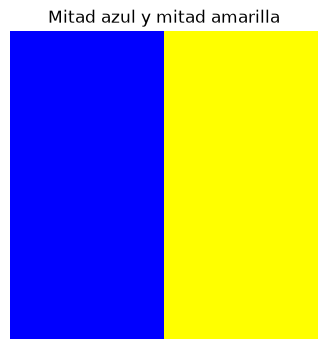

In [5]:
# Completa: construye la imagen RGB de dos mitades
rgb = np.zeros((4, 4, 3), dtype=np.uint8)
rgb[:, 0:2] = [0, 0, 255] # mitad izquierda: elige un color (R,G,B)
rgb[:, 2:4] = [255, 255, 0] # mitad derecha: elige otro color

print("Shape:", rgb.shape)
print("Pixel [0,0]:", rgb[0, 0])
print("Pixel [0,3]:", rgb[0, 3])

plt.figure(figsize=(4, 4))
plt.imshow(rgb, interpolation="nearest")
plt.title("Mitad azul y mitad amarilla")
plt.axis("off")
plt.show()

Canal R:
[[  0   0 255 255]
 [  0   0 255 255]
 [  0   0 255 255]
 [  0   0 255 255]]
Canal G:
[[  0   0 255 255]
 [  0   0 255 255]
 [  0   0 255 255]
 [  0   0 255 255]]
Canal B:
[[255 255   0   0]
 [255 255   0   0]
 [255 255   0   0]
 [255 255   0   0]]


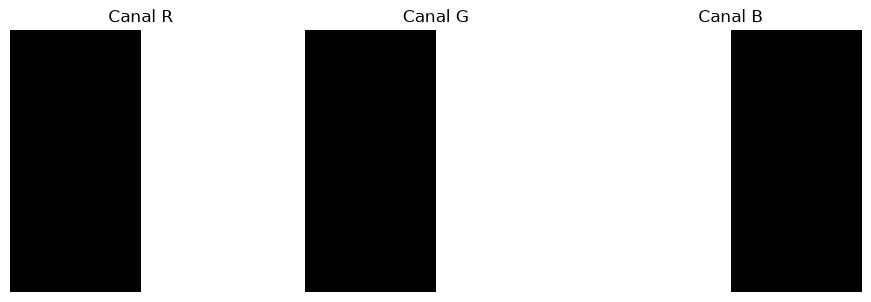

In [6]:
# Completa: extrae cada canal
canal_r = rgb[:, :, 0]
canal_g = rgb[:, :, 1]
canal_b = rgb[:, :, 2]

print("Canal R:")
print(canal_r)

print("Canal G:")
print(canal_g)

print("Canal B:")
print(canal_b)

fig, ejes = plt.subplots(1, 3, figsize=(9, 3))

for eje, canal, nombre in zip(
    ejes,
    [canal_r, canal_g, canal_b],
    ["Canal R", "Canal G", "Canal B"]
):
    eje.imshow(
        canal,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )
    eje.set_title(nombre)
    eje.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Completa: gris_promedio y gris_luminosidad
gris_promedio = rgb.mean(axis=2).astype(np.uint8)

luminosidad_decimal = (
    0.299 * rgb[:, :, 0].astype(float)
    + 0.587 * rgb[:, :, 1].astype(float)
    + 0.114 * rgb[:, :, 2].astype(float)
)

gris_luminosidad = luminosidad_decimal.astype(np.uint8)

print("Promedio simple:")
print(gris_promedio)

print("Luminosidad ponderada en uint8:")
print(gris_luminosidad)

print(
    "Luminosidad del azul antes de convertir:",
    f"{luminosidad_decimal[0, 0]:.2f}"
)
print(
    "Luminosidad del amarillo antes de convertir:",
    f"{luminosidad_decimal[0, 3]:.2f}"
)

Promedio simple:
[[ 85  85 170 170]
 [ 85  85 170 170]
 [ 85  85 170 170]
 [ 85  85 170 170]]
Luminosidad ponderada en uint8:
[[ 29  29 225 225]
 [ 29  29 225 225]
 [ 29  29 225 225]
 [ 29  29 225 225]]
Luminosidad del azul antes de convertir: 29.07
Luminosidad del amarillo antes de convertir: 225.93


Umbral: 100
[[  0   0 255 255]
 [  0   0 255 255]
 [  0   0 255 255]
 [  0   0 255 255]]


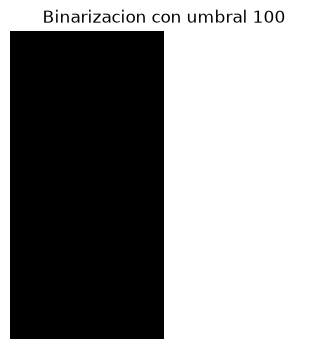

In [8]:
# Completa: binarizacion con tu propio umbral
umbral = 100

binaria = (
    (gris_luminosidad >= umbral).astype(np.uint8) * 255
)

print("Umbral:", umbral)
print(binaria)

plt.figure(figsize=(4, 4))
plt.imshow(
    binaria,
    cmap="gray",
    vmin=0,
    vmax=255,
    interpolation="nearest"
)
plt.title(f"Binarizacion con umbral {umbral}")
plt.axis("off")
plt.show()